# Closed-Form Analogue of the Radial CO$_2$ Injection Benchmark: Saturation Front at 100 Days

Active subspaces for a closed-form (exact Buckley–Leverett) analogue of the carbon dioxide storage benchmark of

**Markus Köppel**¹, **Fabian Franzelin**², **Ilja Kröker**¹, **Sergey Oladyshkin**³, **Gabriele Santin**¹, **Dominik Wittwar**¹, **Andrea Barth**¹, **Bernard Haasdonk**¹, **Wolfgang Nowak**³, **Dirk Pflüger**², **Christian Rohde**¹

¹ IANS, Universität Stuttgart, Pfaffenwaldring 57, 70569 Stuttgart, Germany
² IPVS, Universität Stuttgart, Universitätsstraße 38, 70569 Stuttgart, Germany
³ IWS, Universität Stuttgart, Pfaffenwaldring 5a, 70569 Stuttgart, Germany

M. Köppel et al., "Comparison of data-driven uncertainty quantification methods for a carbon dioxide storage benchmark scenario", *Computational Geosciences* 23(2):339–354, 2019, [doi:10.1007/s10596-018-9785-x](https://doi.org/10.1007/s10596-018-9785-x). (Read from the open-access preprint, arXiv:1802.03064v1; page and equation numbers below are the preprint's.)

> **Not the authors' model.** The data are the closed-form (exact entropy) solution of the paper's Eq. (11) evaluated at the benchmark's 10,000 input samples, **not** the paper's finite-volume reference model. A flux factor $C_Q = 0.643$ (the paper's equations have 1) and the map from the coded porosity samples to porosity were fitted to the authors' Monte Carlo curves. The closed form is a different model from the authors': at $r = 100$ m its standard deviation of $S$ is 0.271 against the reference's 0.309, and it misses the reference also where its solution is smooth (see the check below).

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Supercritical CO$_2$ is injected for 100 days into a radially symmetric saline aquifer, where the CO$_2$ saturation obeys a Buckley–Leverett conservation law (the paper's Eq. 11) with three uncertain inputs given as 10,000 data samples by the benchmark: the injection rate, the relative permeability degree and the porosity. The data here are the closed-form (exact entropy) solution of Eq. (11) evaluated on the benchmark's input samples, not the paper's finite-volume reference model, with a flux factor $C_Q = 0.643$ (paper: 1) and the porosity map fitted to the authors' Monte Carlo curves; it matches their joint mean at 100 m by construction but not their standard deviation (0.271 against 0.309), so it is a different model from theirs. For this closed-form analogue, the active subspaces of the saturation at $r = 100$ m (from values, by the global quadratic estimator) and of the front radius (from exact gradients) are one-dimensional and almost entirely porosity, with a small injection-rate weight and a negligible relative-permeability weight; with only three inputs, the result is a ranking of inputs more than a dimension reduction.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\, \nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x) \approx g(\mathbf W_1^T \mathbf x)$, and a scatter plot of $f$ against $\mathbf W_1^T\mathbf x$ (a sufficient summary plot) shows the dependence. When only values are available, $\mathbf C$ can be estimated from a fitted global quadratic or from local linear fits. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

## The model

**Equations** (paper Sec. 2–3, Table 1). CO$_2$ and brine are incompressible and immiscible, capillary pressure is neglected, and the aquifer is homogeneous. With the analytic radial pressure of Eq. (13), the total flux is $Q/r$ and the CO$_2$ saturation $S(r,t)$ obeys Eq. (11). Its in-domain source term $-q_{CO_2}$ is read here as acting only at the well, i.e. through the left boundary value (an interpretation; the paper does not say):

$$\phi\,\frac{\partial S}{\partial t} + \frac{Q}{r}\,\frac{\partial f(S;n)}{\partial r} = 0, \qquad S(r,0)=0,\quad S(0,t)=0.8,$$

$$f(S;n) = \frac{S^{n}/\mu_g}{S^{n}/\mu_g + (1-S)^{n}/\mu_w}, \qquad Q = C_p\, q_{CO_2}\,(1+\theta_1),$$

with $\mu_g = 3.95\cdot10^{-5}$ Pa s, $\mu_w = 2.535\cdot 10^{-4}$ Pa s, and $C_p q_{CO_2} = (p_{max}-p_{min}) K_A \lambda / \ln r_{max} = 6.436\cdot10^{-5}$ m$^2$/s from Table 1 (the paper's $C_p = 3.48\cdot 10^{-3}$ with $q_{CO_2} = 1600$ m$^3$/d). $Q$ has units m$^2$/s because $C_p$ has units 1/m; the paper\'s Fig. 1 labels the injection rate in m$^3$/s. The uncertain inputs are $\theta_1$ (injection rate, Eq. 13), the relative permeability degree $n = \theta_2$ (Eqs. 14–15) and the porosity $\phi = \theta_3$.

**Solver: not the authors'.** The authors solve Eq. (11) numerically with a central-upwind finite-volume scheme ($\Delta r = 1$ m, second-order Runge–Kutta); that code (executables only) was not run here. `co2_benchmark_model.py` instead evaluates the closed-form exact entropy solution: with $\xi = \phi r^2/(2 C_Q Q t)$, $S = 0.8$ for $\xi \le f'(0.8)$, $f'(S) = \xi$ on the rarefaction, and a shock from $S_s$ to 0 at $\xi_s = f(S_s)/S_s$, where $f'(S_s)S_s = f(S_s)$ (Welge tangent). The front radius is $r_f = \sqrt{2 C_Q Q t\, \xi_s(n)/\phi}$. The check below shows that this is a different model from the authors': no single set of constants makes it match all their reference curves.

**What the paper does not state, and how it is fixed here** (details in `DATA.md`). The benchmark's samples (`InputParameters.csv` of the Zenodo archive) are coded: `ir` $=\theta_1$, `kd` maps to $n = 2 + 2\,$`kd` (Fig. 1 shows $n \in [2,4]$), and `po` maps to porosity by an affine map that is not given. Fitting the exact solution to the authors' Monte Carlo reference curves (mean and standard deviation over 0–250 m, joint case plus injection-rate-only case with $\phi = 0.15$) gives $\phi = 0.09151 + 0.19647\,$`po` and a flux factor $C_Q = 0.64299$ multiplying $Q$ (the paper's equations have $C_Q = 1$; with $C_Q=1$ the fronts lie $1/\sqrt{C_Q} = 1.25$ times farther out than in the authors' reference). The fitted porosity range, 0.0003–0.76, is somewhat wider than the span of the porosity bars in the paper's Fig. 1 (read from the figure: about 0–0.73), and the bin counts of Fig. 1 differ from those of the archived samples (printed below), so the figure is weak evidence for the map. This is a calibration of a different, simpler model, not the authors' code.

**Quantities of interest** at $t = 100$ days: the CO$_2$ saturation $S(100\text{ m})$, near where the reference standard deviation peaks (paper Fig. 2), and the front radius $r_f$ (m). The input table below is printed from the model module.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import co2_benchmark_model as cm
from generate_data import read_csv

SEED = 933827                       # the only seed; used for every rng=
t_start = time.perf_counter()

print(f'Q0 = Cp qCO2 = {cm.Q0:.4e} m^2/s, t = {cm.T_END / 86400:.0f} d, S(left) = {cm.S_LEFT}, '
      f'mu_w/mu_g = {cm.MU_W / cm.MU_G:.3f}; fitted C_Q = {cm.C_Q}, phi = {cm.A_PHI} + {cm.B_PHI} po')
print(f'fronts with C_Q = 1 (Eq. 11 as written) lie 1/sqrt(C_Q) = {1 / np.sqrt(cm.C_Q):.2f} times farther out; '
      f'shock saturation S_s(n = 2, 4) = {cm.shock(2.0)[0]:.2f}, {cm.shock(4.0)[0]:.2f}')
maps = ['Q0 (1 + ir)', '2 + 2 kd', f'{cm.A_PHI} + {cm.B_PHI} po']
print(f'{"name":5s} {"units":7s} {"from coded sample":24s} description')
for name, unit, mp, desc in zip(cm.NAMES, cm.UNITS, maps, cm.DESCRIPTIONS):
    print(f'{name:5s} {unit:7s} {mp:24s} {desc}')

Q0 = Cp qCO2 = 6.4364e-05 m^2/s, t = 100 d, S(left) = 0.8, mu_w/mu_g = 6.418; fitted C_Q = 0.64299, phi = 0.09151 + 0.19647 po
fronts with C_Q = 1 (Eq. 11 as written) lie 1/sqrt(C_Q) = 1.25 times farther out; shock saturation S_s(n = 2, 4) = 0.37, 0.51
name  units   from coded sample        description
Q     m^2/s   Q0 (1 + ir)              injection rate Q = Cp qCO2 (1 + theta1) (Eq. 13; Fig. 1 axis 'injection rate')
n     1       2 + 2 kd                 relative permeability degree theta2 (Eqs. 14-15)
phi   1       0.09151 + 0.19647 po     reservoir porosity theta3


## Load the data

`inputs.csv` holds the benchmark's 10,000 samples in physical units, `outputs.csv` the saturations at $r$ = 50, 75, 100, 125, 150 m and the front radius, `gradients.csv` the gradient of $r_f$, all written by `generate_data.py`. `benchmark_input_samples.csv` and `mc_reference_mean_std.csv` are the coded samples and the authors' Monte Carlo reference, converted losslessly from the Zenodo archive.

In [2]:
X = read_csv('inputs.csv')                      # (Q m^2/s, n, phi)
F = read_csv('outputs.csv')                     # S at cm.RADII, r_front (m)
G = read_csv('gradients.csv')                   # d r_front / d(Q, n, phi)
Cd = read_csv('benchmark_input_samples.csv')    # coded (ir, kd, po)
MC = read_csv('mc_reference_mean_std.csv')      # x, eal, sal, eir, sir, ekd, skd, epo, spo
print('X', X.shape, 'F', F.shape, 'G', G.shape, 'coded', Cd.shape, 'MC reference', MC.shape)
assert np.array_equal(X, np.column_stack(cm.coded_to_physical(*Cd.T)))
names = list(cm.NAMES)
labels = ['$Q$', '$n$', r'$\phi$']
for j, nm in enumerate(names):
    print(f'{nm:4s} min {X[:, j].min():.4g}  mean {X[:, j].mean():.4g}  sd {X[:, j].std():.4g}  '
          f'max {X[:, j].max():.4g}  sd/mean {X[:, j].std() / X[:, j].mean():.3f}')
phi = X[:, 2]
print(f'porosity < 0.01: {(phi < 0.01).sum()} samples, < 0.05: {(phi < 0.05).sum()}; '
      f'front beyond r_max = 500 m: {(F[:, 5] > 500).sum()}, beyond 250 m: {(F[:, 5] > 250).sum()}')

X (10000, 3) F (10000, 6) G (10000, 3) coded (10000, 3) MC reference (250, 9)
Q    min 6.74e-05  mean 0.0001074  sd 1.158e-05  max 0.0001286  sd/mean 0.108
n    min 2.001  mean 3.002  sd 0.5361  max 3.999  sd/mean 0.179
phi  min 0.0003414  mean 0.2021  sd 0.1146  max 0.759  sd/mean 0.567
porosity < 0.01: 41 samples, < 0.05: 603; front beyond r_max = 500 m: 30, beyond 250 m: 305


### Check: the model against the files and against the authors' Monte Carlo reference

First the model is re-solved at five samples and compared with `outputs.csv`. Then the saturation field over the benchmark's 250 output points is computed for all 10,000 samples and its mean and standard deviation are compared with the authors' reference (paper Fig. 2). The joint case uses the samples as they are. The single-input cases hold the other inputs fixed at values the paper does not give; the held values below were fitted by `calibrate.py` to these same curves (porosity held at 0.15 where it is not the uncertain input). The saturation fields are kept for the checks that follow.

In [3]:
rows = [0, 1, 2, 4321, 9999]
diff = max(np.max(np.abs(cm.qoi(*X[i]) - F[i]) / np.maximum(np.abs(F[i]), 1e-300)) for i in rows)
print(f'largest relative difference model vs outputs.csv at rows {rows}: {diff:.1e}')

x = MC[:, 0]
N = len(X)
HELD = {'eir': dict(n=2.531), 'ekd': dict(g=0.6806), 'epo': dict(g=0.6806, n=2.437)}
Q0g = lambda g: np.full(N, cm.Q0 * g)
cases = {
    'joint (all three)': (1, X[:, 0], X[:, 1], phi),
    'injection rate only': (3, X[:, 0], np.full(N, HELD['eir']['n']), np.full(N, 0.15)),
    'rel. perm. degree only': (5, Q0g(HELD['ekd']['g']), X[:, 1], np.full(N, 0.15)),
    'porosity only': (7, Q0g(HELD['epo']['g']), np.full(N, HELD['epo']['n']), phi),
}
t0 = time.perf_counter()
curves, fields = {}, {}
for name, (col, q, n_, p_) in cases.items():
    S = cm.saturation_field(x, q, n_, p_)
    fields[name] = S
    curves[name] = (col, S.mean(0), S.std(0))
print(f'saturation fields, 4 x {N} samples x {len(x)} radii: {time.perf_counter() - t0:.0f} s')
k100 = np.argmin(np.abs(x - 100))
print(f'{"case":24s} rms(mean) rms(std)  at r = {x[k100]:.1f} m: mean model/MC   std model/MC')
for name, (col, m, s) in curves.items():
    print(f'{name:24s} {np.sqrt(np.mean((m - MC[:, col])**2)):.4f}    '
          f'{np.sqrt(np.mean((s - MC[:, col + 1])**2)):.4f}               '
          f'{m[k100]:.3f}/{MC[k100, col]:.3f}     {s[k100]:.3f}/{MC[k100, col + 1]:.3f}')

largest relative difference model vs outputs.csv at rows [0, 1, 2, 4321, 9999]: 0.0e+00


saturation fields, 4 x 10000 samples x 250 radii: 35 s
case                     rms(mean) rms(std)  at r = 100.4 m: mean model/MC   std model/MC
joint (all three)        0.0257    0.0219               0.308/0.308     0.271/0.309
injection rate only      0.0376    0.0248               0.486/0.501     0.044/0.134
rel. perm. degree only   0.0371    0.0118               0.000/0.000     0.000/0.000
porosity only            0.0241    0.0158               0.079/0.074     0.187/0.192


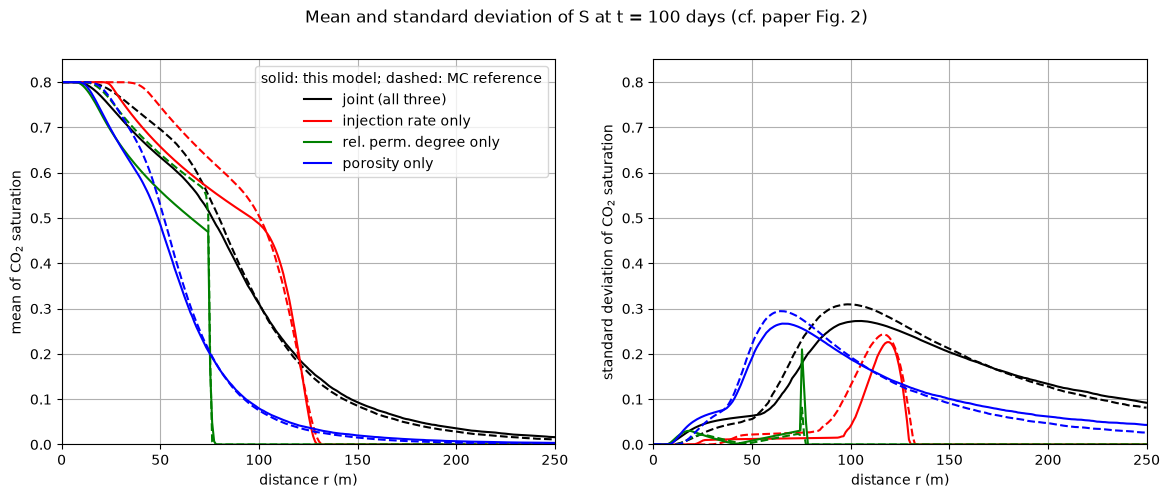

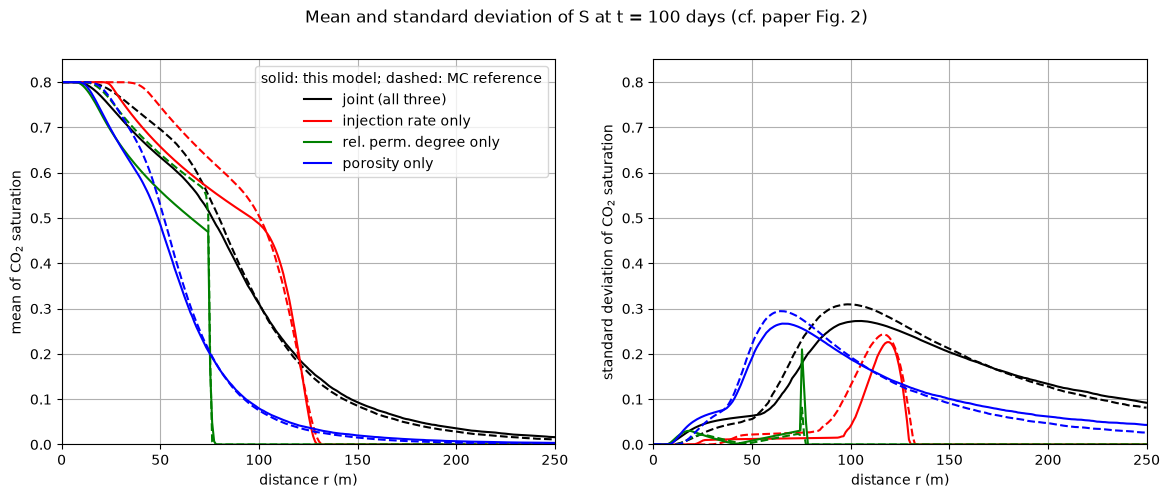

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['k', 'r', 'g', 'b']
for (name, (col, m, s)), c in zip(curves.items(), colors):
    axes[0].plot(x, MC[:, col], '--', color=c, lw=1.5)
    axes[0].plot(x, m, '-', color=c, lw=1.5, label=name)
    axes[1].plot(x, MC[:, col + 1], '--', color=c, lw=1.5)
    axes[1].plot(x, s, '-', color=c, lw=1.5, label=name)
for ax, lab in zip(axes, ['mean', 'standard deviation']):
    ax.set_xlabel('distance r (m)')
    ax.set_ylabel(f'{lab} of CO$_2$ saturation')
    ax.set_xlim(0, 250); ax.set_ylim(0, 0.85); ax.grid(True)
axes[0].legend(title='solid: this model; dashed: MC reference')
fig.suptitle('Mean and standard deviation of S at t = 100 days (cf. paper Fig. 2)')
fig

The model reproduces `outputs.csv` to the digits written (largest relative difference 0 at the five rows). For the joint case, the root-mean-square difference from the authors' reference over the 250 points is 0.026 for the mean and 0.022 for the standard deviation; at $r = 100.4$ m the means are 0.308 and 0.308 and the standard deviations 0.271 here and 0.309 in the reference. These agreements are fits, not independent checks: the joint and injection-rate-only curves determined $C_Q$ and the porosity map, and the held values of the two other single-input cases were fitted to their own curves. What the fit could not adjust disagrees: the standard deviation at 100.4 m is low in the joint case and much lower in the injection-rate-only case (0.044 here, 0.134 in the reference). The next cells test whether front smearing explains this (it does not) and whether one flux factor fits all cases (it does not).

### What the closed form does not reproduce

A finite-volume solution on a 1 m grid smears the front. If smearing caused the difference, smoothing the exact profiles along $r$ should move their standard deviation towards the reference. The second part compares the injection-rate-only case at radii that every front has passed, where the closed-form solution is smooth (rarefaction or the $S = 0.8$ plateau).

In [5]:
from scipy.ndimage import gaussian_filter1d

S_joint = fields['joint (all three)']
print(f'grid spacing {x[1] - x[0]:.4f} m; joint std of S after smoothing every profile along r '
      f'with a Gaussian of sigma cells:')
for sig in (0, 1, 2, 4, 8):
    Sg = S_joint if sig == 0 else gaussian_filter1d(S_joint, sig, axis=1, mode='nearest')
    s_ = Sg.std(0)
    print(f'  sigma = {sig}: std at {x[k100]:.1f} m {s_[k100]:.3f}, peak {s_.max():.3f} at {x[s_.argmax()]:.0f} m')
print(f'  reference: std at {x[k100]:.1f} m {MC[k100, 2]:.3f}, peak {MC[:, 2].max():.3f} at {x[MC[:, 2].argmax()]:.0f} m; '
      f'ratio model/reference at {x[k100]:.1f} m {curves["joint (all three)"][2][k100] / MC[k100, 2]:.3f}')

S_ir = fields['injection rate only']
_, q_ir, n_ir, p_ir = cases['injection rate only']
rf_ir = np.array([cm.front_radius(q, n_ir[0], p_ir[0]) for q in (q_ir.min(), q_ir.max())])
print(f'\ninjection rate only: fronts between {rf_ir[0]:.1f} and {rf_ir[1]:.1f} m')
for r0 in (60, 80, 100):
    kk = np.argmin(np.abs(x - r0))
    print(f'  r = {x[kk]:5.1f} m: mean {S_ir[:, kk].mean():.3f} (reference {MC[kk, 3]:.3f}), '
          f'std {S_ir[:, kk].std():.3f} (reference {MC[kk, 4]:.3f}), reference/model std '
          f'{MC[kk, 4] / S_ir[:, kk].std():.2f}; samples behind the front {np.mean(S_ir[:, kk] > 0):.3f}')

grid spacing 1.0040 m; joint std of S after smoothing every profile along r with a Gaussian of sigma cells:
  sigma = 0: std at 100.4 m 0.271, peak 0.273 at 105 m
  sigma = 1: std at 100.4 m 0.269, peak 0.270 at 103 m
  sigma = 2: std at 100.4 m 0.266, peak 0.267 at 104 m
  sigma = 4: std at 100.4 m 0.260, peak 0.261 at 105 m


  sigma = 8: std at 100.4 m 0.246, peak 0.250 at 107 m
  reference: std at 100.4 m 0.309, peak 0.309 at 98 m; ratio model/reference at 100.4 m 0.878

injection rate only: fronts between 93.9 and 129.7 m
  r =  60.2 m: mean 0.616 (reference 0.695), std 0.013 (reference 0.024), reference/model std 1.85; samples behind the front 1.000
  r =  80.3 m: mean 0.548 (reference 0.608), std 0.014 (reference 0.028), reference/model std 1.96; samples behind the front 1.000
  r = 100.4 m: mean 0.486 (reference 0.501), std 0.044 (reference 0.134), reference/model std 3.06; samples behind the front 0.993


Smoothing lowers the joint standard deviation at 100.4 m (0.271 without smoothing; 0.269, 0.266, 0.260 and 0.246 for $\sigma$ = 1, 2, 4 and 8 cells), moving it away from the reference's 0.309: front smearing does not explain the deficit, which is 12 % at 100.4 m (ratio 0.878). In the injection-rate-only case every front lies between 93.9 and 129.7 m, so at 60 and 80 m all samples (fraction 1.000) are behind the front, where the closed-form solution is smooth. There the means still differ (0.616 against 0.695 at 60.2 m, 0.548 against 0.608 at 80.3 m) and the reference's standard deviation is 1.85 and 1.96 times this model's (0.024 against 0.013; 0.028 against 0.014). This difference is structural: the authors' flux function, source term or held values are not what the closed form assumes. The 12 % deficit of the joint standard deviation and the threefold deficit at 100.4 m in the injection-rate-only case (0.044 against 0.134) are unexplained; the closed form is a different model from the authors'.

In [6]:
import calibrate as cal          # the calibration's tabulated exact solution (calibrate.py)

t0 = time.perf_counter()
res = cal.cq_consistency()
print('C_Q fitted alone to each reference case, other inputs held at natural values (g = 1 + theta1):')
for name, cq1, rms in res:
    print(f'  {name:40s} C_Q = {cq1:.3f}  rms = {rms:.4f}')
print(f'  ratio joint / degree only: {res[0][1] / res[2][1]:.2f}  ({time.perf_counter() - t0:.0f} s)')
print(f'held g = {HELD["ekd"]["g"]} used above is theta1 = {HELD["ekd"]["g"] - 1:+.2f}; '
      f'sample range of theta1: {Cd[:, 0].min():.3f} to {Cd[:, 0].max():.3f}')

# bar heights of the paper's Fig. 1 (p. 6), read from a 600-dpi render (review); the injection-rate
# panel only for its first five bars
FIG1 = {'ir': [25, 112, 363, 718, 1067], 'po': [1050, 2433, 2469, 1835, 1217, 587, 281, 100, 33, 6]}
print('\n10 equal-width bins from min to max (the same under any increasing affine map):')
for j, nm in [(0, 'ir'), (2, 'po')]:
    print(f'  {nm}  archive samples {np.histogram(Cd[:, j], 10)[0]}')
    print(f'  {nm}  paper Fig. 1    {np.array(FIG1[nm])}')

C_Q fitted alone to each reference case, other inputs held at natural values (g = 1 + theta1):
  joint (porosity map fixed)               C_Q = 0.643  rms = 0.0239
  injection rate only, phi 0.15, n 3       C_Q = 0.647  rms = 0.0335
  rel. perm. degree only, g 1, phi 0.15    C_Q = 0.436  rms = 0.0274
  porosity only, g 1, n 2                  C_Q = 0.462  rms = 0.0210
  porosity only, g 1, n 3                  C_Q = 0.446  rms = 0.0219
  ratio joint / degree only: 1.47  (20 s)
held g = 0.6806 used above is theta1 = -0.32; sample range of theta1: 0.047 to 0.998

10 equal-width bins from min to max (the same under any increasing affine map):
  ir  archive samples [  27  110  339  624 1102 1453 1832 1982 1749  782]
  ir  paper Fig. 1    [  25  112  363  718 1067]
  po  archive samples [1257 2574 2504 1826 1056  493  201   70   16    3]
  po  paper Fig. 1    [1050 2433 2469 1835 1217  587  281  100   33    6]


Fitted alone to each case with the other inputs held at natural values ($g = 1 + \theta_1 = 1$, $\phi = 0.15$, $n = 2$ or 3), the flux factor is 0.643 for the joint curves and 0.647 for the injection-rate-only curves but 0.436 for the degree-only curves and 0.446–0.462 for the porosity-only curves (ratio joint / degree only 1.47). One $C_Q$ fits all four cases above only because the held injection factor $g = 0.6806$ ($\theta_1 = -0.32$) absorbs that ratio, and $\theta_1 = -0.32$ lies outside the benchmark's sample range (0.047–0.998). The paper's Fig. 1 does not show the archived samples under the affine maps used here, or under any increasing affine map, since equal-width bin counts do not change under such maps: the porosity counts are 1257, 2574, 2504, … in the archive and 1050, 2433, 2469, … in the figure. Whether the reference curves were computed on the archived samples is a question for the authors.

## Estimate the active subspace of $S(100\text{ m})$

**Scaling.** The inputs follow the benchmark's empirical distributions, which are neither uniform nor Gaussian (paper Fig. 1). Every input is scaled the same way, by its sample mean and standard deviation, $x_j = (X_j - \bar X_j)/s_j$, through `ac.Gaussian` with the sample means and variances.

**Estimator and its assumptions.** $S(100\text{ m})$ jumps from $S_s \approx 0.37$–$0.51$ to 0 when the front passes $r = 100$ m. Its gradient has a delta on the surface $r_f = 100$ m, so $\mathbf C = E[\nabla S\,\nabla S^T]$ does not exist for this QoI. We therefore use values only: the global quadratic estimator `qphd` (Li 1992; $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\mathbf H$ for a quadratic fitted to all 10,000 samples, far above the minimum of $(m+1)(m+2)/2 = 10$), with 200 bootstrap replicates. Its eigenvalues describe the fitted quadratic, not an active subspace of $S$. The principal-Hessian-direction theory behind `qphd` assumes Gaussian inputs, and the library flags the estimator as valid only for them; declaring `ac.Gaussian` with the sample moments silences that warning but does not make the inputs Gaussian (skewness and kurtosis are printed below; a Gaussian has 0 and 3). The direction is therefore checked two other ways below: by local linear gradients, and by the normal of the front surface together with finite-difference gradients of $S$ behind the front.

In [7]:
space = ac.Gaussian(X.mean(axis=0), X.var(axis=0), names=names, units=list(cm.UNITS))
f = F[:, 2]                                         # S(100 m)
from scipy import stats
print('skewness', np.round(stats.skew(X, axis=0), 2), ' kurtosis', np.round(stats.kurtosis(X, axis=0, fisher=False), 2), ' (Q, n, phi)')
print(f'S(100 m) = 0 (front not yet at 100 m): {np.mean(f == 0):.3f} of samples; '
      f'S = 0.8: {np.mean(f == 0.8):.4f}')
sub = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', nboot=200, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=-f, columns=3)   # S decreases along w1
lam = sub.eigenvalues
lo, hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print('eigenvalues      ', np.array2string(lam, precision=4))
print('95% bootstrap lo ', np.array2string(lo, precision=4))
print('95% bootstrap hi ', np.array2string(hi, precision=4))
print(f'lambda1/lambda2 = {lam[0] / lam[1]:.0f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}, n = {sub.n}')
print('w1:', ', '.join(f'{nm} {w:+.3f}' for nm, w in zip(names, sub.W[:, 0])))
Z = space.to_normalized(X)
A2 = np.column_stack([np.ones(N)] + [Z[:, i] for i in range(3)] + [Z[:, i] * Z[:, j] for i in range(3) for j in range(i, 3)])
res2 = f - A2 @ np.linalg.lstsq(A2, f, rcond=None)[0]
print(f'in-sample R^2 of the quadratic behind qphd: {1 - res2.var() / f.var():.3f}')

skewness [-0.49 -0.01  0.74]  kurtosis [2.65 1.91 3.39]  (Q, n, phi)
S(100 m) = 0 (front not yet at 100 m): 0.424 of samples; S = 0.8: 0.0027


eigenvalues       [8.3274e-02 1.1692e-04 2.3715e-05]
95% bootstrap lo  [8.1822e-02 9.0643e-05 2.7060e-06]
95% bootstrap hi  [8.4821e-02 1.7501e-04 8.3205e-05]
lambda1/lambda2 = 712, lambda2/lambda3 = 4.93, n = 1
w1: Q -0.127, n -0.009, phi +0.992
in-sample R^2 of the quadratic behind qphd: 0.797


## Results

### Eigenvalues

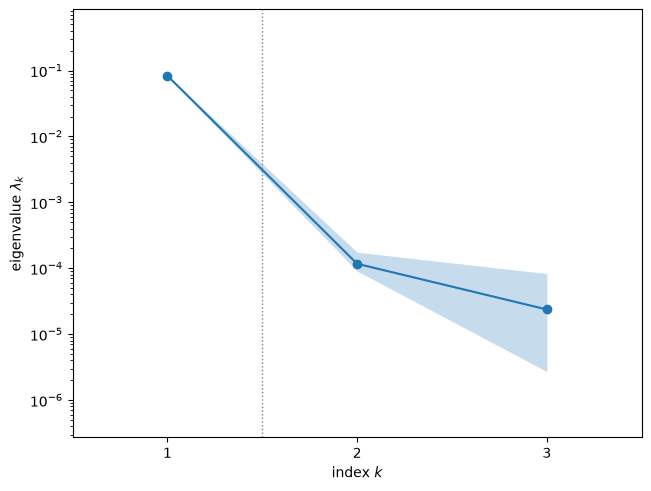

In [8]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
fig

The first eigenvalue of the fitted quadratic's matrix, $8.33\cdot10^{-2}$ (bootstrap interval $8.18$–$8.48\cdot10^{-2}$), is 712 times the second, $1.17\cdot10^{-4}$ (interval $0.91$–$1.75\cdot10^{-4}$), so the gap is far larger than the bootstrap spread; $\lambda_2/\lambda_3 = 4.93$. The eigenvalue-gap rule picks $n = 1$. These numbers describe the quadratic, whose in-sample $R^2$ is 0.797, not an eigenvalue ratio of $S(100\text{ m})$ itself (for which $\mathbf C$ does not exist); what carries over to $S$ is the direction, checked below. The inputs are not Gaussian (porosity skewness 0.74, injection-rate skewness −0.49, degree kurtosis 1.91, close to a uniform's 1.8), so the Gaussian theory behind `qphd` holds only approximately.

### Subspace errors

median bootstrap subspace distance for n = 1, 2: [0.005 0.096]


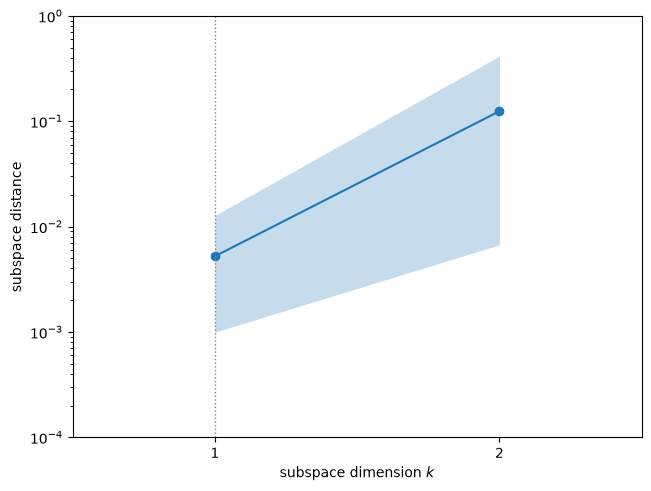

In [9]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
d = sub.bootstrap_distances
print('median bootstrap subspace distance for n = 1, 2:', np.round(np.median(d, axis=0), 4))
fig

The median bootstrap subspace distance is 0.005 for $n = 1$ and 0.096 for $n = 2$: the first direction is well determined from 10,000 samples, the second much less so.

### Eigenvectors

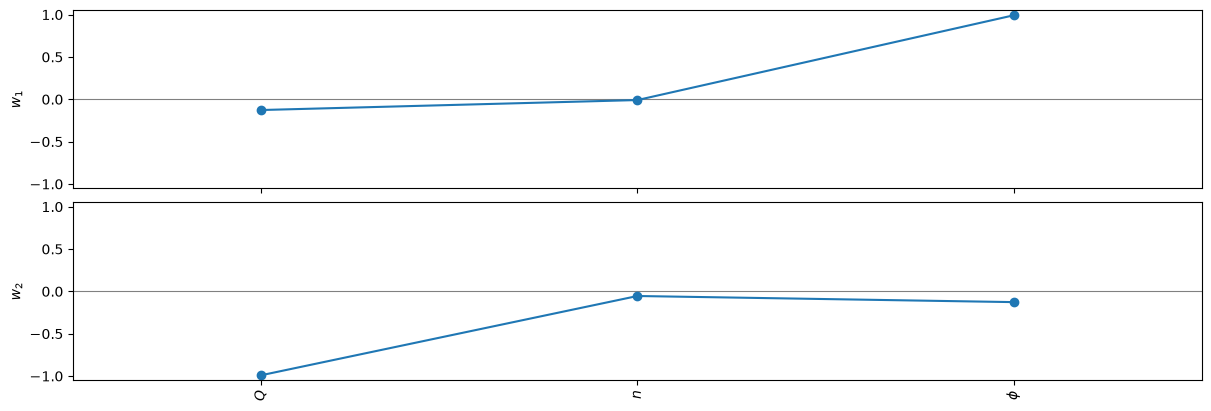

In [10]:
fig, ax = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(12, 4))
fig

$\mathbf w_1 = (-0.127, -0.009, +0.992)$ for $(Q, n, \phi)$: $S(100\text{ m})$ falls as porosity rises (a slower front) and rises with the injection rate, and the relative permeability degree has weight 0.009. The weights are per standard deviation of each input, and the benchmark's porosity varies much more, relative to its mean, than its injection rate (sd/mean 0.567 against 0.108 in the load cell), which is part of why porosity dominates. $\mathbf w_2$ is mostly the injection rate.

### Sufficient summary plot

corr(w1^T x, S(100 m)) = -0.853; S = 0 for all samples with y > 0.26, S > 0 for all with y < -0.10


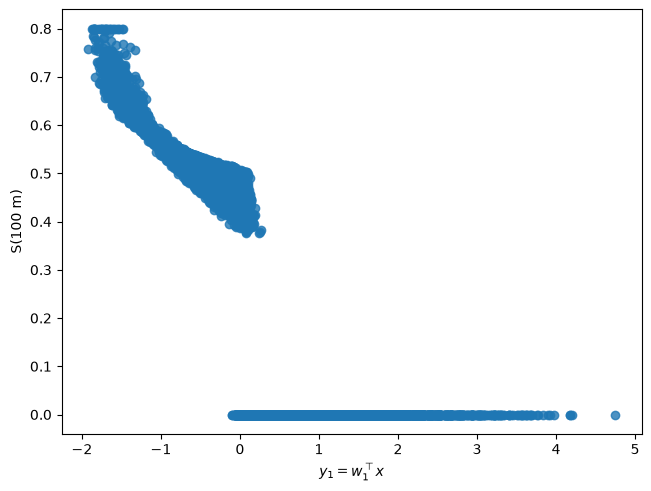

In [11]:
y = space.to_normalized(X) @ sub.W[:, 0]
print(f'corr(w1^T x, S(100 m)) = {np.corrcoef(y, f)[0, 1]:.3f}; '
      f'S = 0 for all samples with y > {y[f > 0].max():.2f}, S > 0 for all with y < {y[f == 0].min():.2f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='S(100 m)')
fig

The summary plot has two branches. For $y = \mathbf w_1^T\mathbf x > 0.26$ every sample has $S = 0$ (the front has not reached 100 m; 42.4 % of the samples), and for $y < -0.10$ every sample has $S > 0$; only in the band $-0.10 < y < 0.26$ does the arrival of the front depend on the other directions. Behind the front, $S$ falls along $y$ from 0.8 to about 0.4 within a band of finite width. The correlation of $y$ with $S$ is $-0.853$; a single linear trend does not describe the jump, but a function of $y$ alone nearly does.

### Cross-check: local linear gradients

In [12]:
gl = ac.local_linear_gradients(X=X, f=f, space=space, p=100)
sub_ll = ac.active_subspace(grads=gl, nboot=200, rng=SEED)
lam_ll = sub_ll.eigenvalues
print('local linear (p = 100) eigenvalues', np.array2string(lam_ll, precision=4),
      f' lambda1/lambda2 = {lam_ll[0] / lam_ll[1]:.0f}')
print('w1:', ', '.join(f'{nm} {w:+.3f}' for nm, w in zip(names, sub_ll.W[:, 0])),
      f'; |w1(ll) . w1(qphd)| = {abs(sub_ll.W[:, 0] @ sub.W[:, 0]):.4f}')

local linear (p = 100) eigenvalues [0.1475 0.0014 0.0012]  lambda1/lambda2 = 102
w1: Q -0.178, n +0.011, phi +0.984 ; |w1(ll) . w1(qphd)| = 0.9985


Local linear fits with 100 neighbours give the same direction ($|\mathbf w_1^{ll}\cdot\mathbf w_1| = 0.9985$; $\mathbf w_1^{ll} = (-0.178, +0.011, +0.984)$) with a smaller ratio $\lambda_1/\lambda_2 = 102$: local fits that straddle the jump put noise into the smaller eigenvalues.

### Cross-check: the normal of the front surface, and the smooth part behind it

The jump of $S(100\text{ m})$ happens on the surface $r_f(\mathbf x) = 100$ m, whose unit normal in the scaled inputs is $\nabla r_f/\|\nabla r_f\|$ (exact gradients from `gradients.csv`, scaled by the input standard deviations). Behind the front $S$ is smooth, and its gradient is estimated by central differences (relative step $10^{-6}$; no difference crosses the front).

In [13]:
sd = X.std(axis=0)
near = np.abs(F[:, 5] - 100) < 5
U = G[near] * sd
U /= np.linalg.norm(U, axis=1, keepdims=True)
v = -U.mean(axis=0)                     # S(100 m) falls where r_f falls
v /= np.linalg.norm(v)
print(f'mean unit normal of r_f = 100 m ({near.sum()} samples with |r_f - 100| < 5 m): '
      + ', '.join(f'{nm} {c:+.3f}' for nm, c in zip(names, v)) + f'; |v . w1| = {abs(v @ sub.W[:, 0]):.3f}')
Xb = X[f > 0]
gS = np.zeros_like(Xb)
r100 = np.array([100.0])
for j in range(3):
    h = 1e-6 * Xb[:, j]
    Xp, Xm = Xb.copy(), Xb.copy()
    Xp[:, j] += h
    Xm[:, j] -= h
    Sp, Sm = cm.saturation_field(r100, *Xp.T)[:, 0], cm.saturation_field(r100, *Xm.T)[:, 0]
    assert np.all(Sp > 0) and np.all(Sm > 0)          # no difference crosses the front
    gS[:, j] = (Sp - Sm) / (2 * h)                     # physical units; the space scales them
sub_b = ac.active_subspace(space=space, grads=gS, nboot=200, rng=SEED)
wb = sub_b.W[:, 0] * np.sign(sub_b.W[2, 0])
lb = sub_b.eigenvalues
print(f'behind the front ({len(Xb)} samples with S > 0): lambda1/lambda2 = {lb[0] / lb[1]:.0f}; w1: '
      + ', '.join(f'{nm} {c:+.3f}' for nm, c in zip(names, wb)) + f'; |w1(behind) . w1(qphd)| = {abs(wb @ sub.W[:, 0]):.3f}')

mean unit normal of r_f = 100 m (1260 samples with |r_f - 100| < 5 m): Q -0.194, n +0.033, phi +0.981; |v . w1| = 0.997


behind the front (5759 samples with S > 0): lambda1/lambda2 = 49; w1: Q -0.055, n -0.036, phi +0.998; |w1(behind) . w1(qphd)| = 0.997


The mean unit normal of the front surface is $(-0.194, +0.033, +0.981)$ (1260 samples within 5 m of $r_f = 100$ m), with $|\mathbf v\cdot\mathbf w_1| = 0.997$; behind the front, finite-difference gradients of $S$ at the 5759 samples with $S > 0$ give $\mathbf w_1 = (-0.055, -0.036, +0.998)$ with $\lambda_1/\lambda_2 = 49$ and $|\mathbf w_1\cdot\mathbf w_1^{qphd}| = 0.997$. Both the jump and the smooth part vary mainly along porosity, which supports the `qphd` direction independently of its Gaussian assumption.

### A second quantity: the front radius, from exact gradients

$r_f = \sqrt{2 C_Q Q t\,\xi_s(n)/\phi}$ is smooth, and `gradients.csv` holds its exact gradient ($n$-derivative of $\xi_s$ by a central difference; `DATA.md`). Because $\partial r_f/\partial \phi = -r_f/(2\phi)$ and the benchmark's porosity reaches $3\cdot10^{-4}$, the few samples with very small porosity dominate $\mathbf C$. We print that share and repeat the estimate without the samples with $\phi < 0.05$.

In [14]:
rf = F[:, 5]
Gn = G * X.std(axis=0)                     # gradients in the scaled coordinates
share = (Gn[phi < 0.05]**2).sum() / (Gn**2).sum()
print(f'share of trace(C) from the {(phi < 0.05).sum()} samples with phi < 0.05: {share:.5f}')
sub_rf = ac.active_subspace(space=space, grads=G, nboot=200, rng=SEED)
keep = phi >= 0.05
sub_rf5 = ac.active_subspace(space=space, grads=G[keep], nboot=200, rng=SEED)
for lab, s in [('all samples', sub_rf), ('phi >= 0.05', sub_rf5)]:
    s_ = ac.orient(s, by='covariance', X=X if s is sub_rf else X[keep],
                   f=-(rf if s is sub_rf else rf[keep]), columns=3)
    l = s_.eigenvalues
    print(f'{lab:12s} lambda = {np.array2string(l, precision=4)}, l1/l2 = {l[0] / l[1]:.0f}, '
          f'l2/l3 = {l[1] / l[2]:.1f}; w1: ' + ', '.join(f'{nm} {w:+.3f}' for nm, w in zip(names, s_.W[:, 0])))
sub_rf5 = ac.orient(sub_rf5, by='covariance', X=X[keep], f=-rf[keep], columns=3)
print(f'samples with r_f > 500 m (outside the authors\' domain): {(rf > 500).sum()}, '
      f'of which with phi >= 0.05: {(rf[keep] > 500).sum()}')
xs = np.array([cm.shock(k)[1] for k in (2.0, 4.0)])
print(f'log r_f = const + 0.5 log Q - 0.5 log phi + 0.5 log xi_s(n); ranges over the samples: '
      f'0.5 log Q {0.5 * np.log(X[:, 0].max() / X[:, 0].min()):.3f}, '
      f'0.5 log phi {0.5 * np.log(phi.max() / phi.min()):.3f}, '
      f'0.5 log xi_s(n) {0.5 * np.log(xs.max() / xs.min()):.3f}')

share of trace(C) from the 603 samples with phi < 0.05: 0.99983


all samples  lambda = [2.1495e+07 5.3219e+01 2.0275e+00], l1/l2 = 403887, l2/l3 = 26.2; w1: Q -0.000, n +0.000, phi +1.000
phi >= 0.05  lambda = [3.9869e+03 9.1725e+00 1.4741e+00], l1/l2 = 435, l2/l3 = 6.2; w1: Q -0.086, n +0.015, phi +0.996
samples with r_f > 500 m (outside the authors' domain): 30, of which with phi >= 0.05: 0
log r_f = const + 0.5 log Q - 0.5 log phi + 0.5 log xi_s(n); ranges over the samples: 0.5 log Q 0.323, 0.5 log phi 3.853, 0.5 log xi_s(n) 0.036


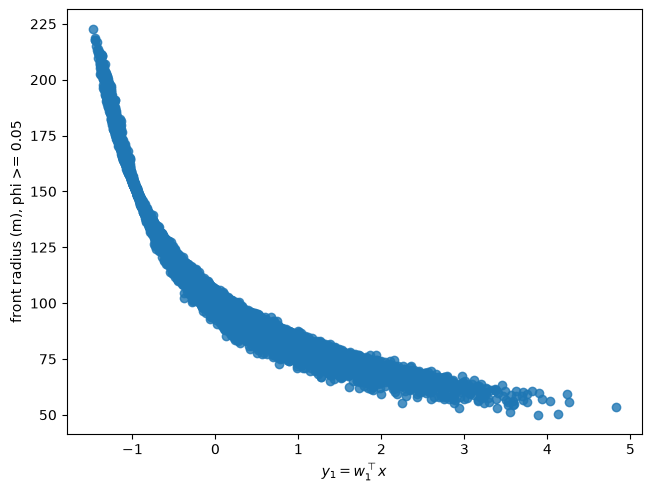

In [15]:
fig, ax = ac.plotting.plot_sufficient_summary(sub_rf5, X=X[keep], f=rf[keep], dims=1,
                                              qoi_label='front radius (m), phi >= 0.05')
fig

For the front radius, the 603 samples with $\phi < 0.05$ carry 0.99983 of the trace of $\mathbf C$, and with all samples $\mathbf w_1$ is the porosity axis to three decimals ($\lambda_1/\lambda_2 = 403887$): this result describes the small-porosity tail. Without those samples, $\lambda_1/\lambda_2 = 435$, $\lambda_2/\lambda_3 = 6.2$ and $\mathbf w_1 = (-0.086, +0.015, +0.996)$, close to the direction found for $S(100\text{ m})$, and the summary plot is a tight monotone curve. The reason is visible in the closed form: $\log r_f$ is $\tfrac12\log Q - \tfrac12\log\phi + \tfrac12\log\xi_s(n)$ plus a constant, and over the samples these three terms range over 0.323, 3.853 and 0.036. The relative permeability degree barely moves the front because the shock speed $\xi_s$ changes little between $n = 2$ and $n = 4$, as the paper's Fig. 2 (Ref 2) shows. Thirty fronts lie beyond the authors' domain radius of 500 m, all with $\phi < 0.05$; the exact solution ignores that boundary (it does not affect $S$ for $r \le 250$ m, because information travels outward), so those 30 values of $r_f$ have no counterpart in the authors' code.

## Surrogate on the active variable

A univariate polynomial of degree 5 in $y = \mathbf w_1^T\mathbf x$, fitted to $S(100\text{ m})$ by least squares, with the leave-one-out $R^2$.

degree 5 polynomial in w1^T x: LOO R^2 = 0.854
degree 3: LOO R^2 = 0.817
degree 7: LOO R^2 = 0.890


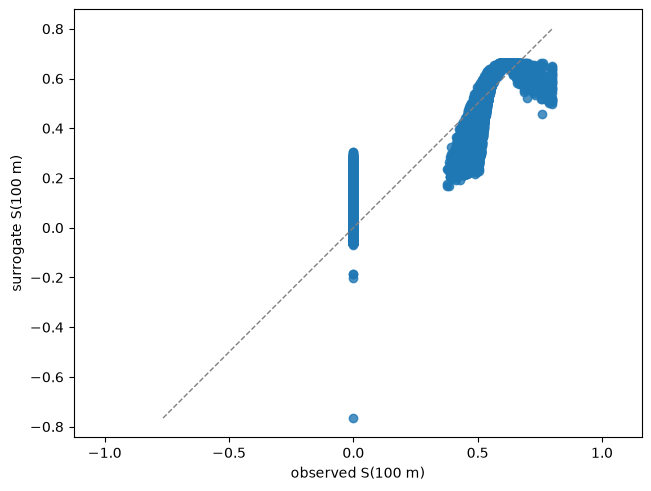

In [16]:
sur = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub, 1), kind='poly', degree=5)
print(f'degree 5 polynomial in w1^T x: LOO R^2 = {sur.loo_r_squared:.3f}')
for deg in (3, 7):
    s_ = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub, 1), kind='poly', degree=deg)
    print(f'degree {deg}: LOO R^2 = {s_.loo_r_squared:.3f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=f, qoi_label='S(100 m)')
fig

The leave-one-out $R^2$ is 0.854 for degree 5 (0.817 for degree 3, 0.890 for degree 7): a polynomial in one variable cannot follow the jump in the band where the front arrives, so the $R^2$ grows slowly with degree. A surrogate for $S(100\text{ m})$ would do better as a classifier for the front's arrival on $y$ plus a smooth fit behind the front.

## Comparison with the paper

The paper reports no active subspace. It reports the Monte Carlo mean and standard deviation of $S$ over distance (Fig. 2; numbers in the Zenodo file) and a qualitative ranking of the inputs (p. 5).

In [17]:
m_j, s_j = curves['joint (all three)'][1:]
kmax_mc, kmax = np.argmax(MC[:, 2]), np.argmax(s_j)
front_kd_mc = x[np.argmax(MC[:, 5] < 0.05)]
front_kd = x[np.argmax(curves['rel. perm. degree only'][1] < 0.05)]
w = sub.W[:, 0]
rows = [
    ('flux factor C_Q', '1 (Eq. 11 as written)', f'{cm.C_Q} (fitted)'),
    ('mean S at r = 100.4 m (joint; fitted)', f'{MC[k100, 1]:.3f}', f'{m_j[k100]:.3f}'),
    ('std S at r = 100.4 m (joint)', f'{MC[k100, 2]:.3f}', f'{s_j[k100]:.3f}'),
    ('peak std of S (joint), location', f'{MC[kmax_mc, 2]:.3f} at {x[kmax_mc]:.0f} m', f'{s_j[kmax]:.3f} at {x[kmax]:.0f} m'),
    ('std S at r = 100.4 m (injection rate only)', f'{MC[k100, 4]:.3f}', f'{curves["injection rate only"][2][k100]:.3f}'),
    ('front, rel. perm. degree only (fitted: C_Q g)', f'{front_kd_mc:.0f} m', f'{front_kd:.0f} m (fit)'),
    ('main inputs (paper p. 5)', 'injection rate and porosity', f'|w1|: phi {abs(w[2]):.3f}, Q {abs(w[0]):.3f}'),
    ('relative permeability degree', 'does not influence S significantly', f'|w1| {abs(w[1]):.3f}'),
    ('active subspace eigenvalues, dimension', 'not reported', f'l1/l2 = {lam[0] / lam[1]:.0f}, n = {sub.n}'),
]
print(f'{"quantity":48s} | {"paper (MC reference file / text)":34s} | notebook')
for r in rows:
    print(f'{r[0]:48s} | {r[1]:34s} | {r[2]}')
print(f'\nnotebook run time: {time.perf_counter() - t_start:.0f} s')

quantity                                         | paper (MC reference file / text)   | notebook
flux factor C_Q                                  | 1 (Eq. 11 as written)              | 0.64299 (fitted)
mean S at r = 100.4 m (joint; fitted)            | 0.308                              | 0.308
std S at r = 100.4 m (joint)                     | 0.309                              | 0.271
peak std of S (joint), location                  | 0.309 at 98 m                      | 0.273 at 105 m
std S at r = 100.4 m (injection rate only)       | 0.134                              | 0.044
front, rel. perm. degree only (fitted: C_Q g)    | 76 m                               | 76 m (fit)
main inputs (paper p. 5)                         | injection rate and porosity        | |w1|: phi 0.992, Q 0.127
relative permeability degree                     | does not influence S significantly | |w1| 0.009
active subspace eigenvalues, dimension           | not reported                       | l1/l2 = 712, n

The joint mean at 100.4 m (0.308 and 0.308) and the relative-permeability-only front (76 m in both) are fits, not checks: the joint curves set $C_Q$ and the porosity map, and in the degree-only case only $C_Q g$ matters, with the held $g$ fitted to those same curves. They are no evidence that the closed form is the authors' model. The quantities that were not fitted disagree: the joint standard deviation at 100.4 m is 0.271 against 0.309 (peak 0.273 at 105 m against 0.309 at 98 m), and the injection-rate-only standard deviation 0.044 against 0.134. For this closed-form analogue, the active subspace agrees with the paper's statement (p. 5) that the injection rate and the porosity are the main sources of uncertainty and that the relative permeability degree does not influence the saturation significantly, and it adds an ordering under the benchmark's distributions: porosity first ($|w_1| = 0.992$), injection rate second (0.127), degree negligible (0.009). Whether the authors' finite-volume model has the same active subspace is not tested here.

## References

1. M. Köppel, F. Franzelin, I. Kröker, S. Oladyshkin, G. Santin, D. Wittwar, A. Barth, B. Haasdonk, W. Nowak, D. Pflüger, C. Rohde. Comparison of data-driven uncertainty quantification methods for a carbon dioxide storage benchmark scenario. *Computational Geosciences* 23(2):339–354, 2019. [doi:10.1007/s10596-018-9785-x](https://doi.org/10.1007/s10596-018-9785-x)
2. M. Köppel et al. Datasets and executables of data-driven uncertainty quantification benchmark in carbon dioxide storage. Zenodo, 2017. [doi:10.5281/zenodo.933827](https://doi.org/10.5281/zenodo.933827)
3. H. Class et al. A benchmark study on problems related to CO2 storage in geologic formations. *Computational Geosciences* 13(4):409–434, 2009. [doi:10.1007/s10596-009-9146-x](https://doi.org/10.1007/s10596-009-9146-x)
4. A. Kurganov, G. Petrova. Central-upwind schemes on triangular grids for hyperbolic systems of conservation laws. *Numerical Methods for Partial Differential Equations* 21(3):536–552, 2005. [doi:10.1002/num.20049](https://doi.org/10.1002/num.20049)
5. K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)
6. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

The paper's authors thank the German Research Foundation (DFG) for financial support within the Cluster of Excellence in Simulation Technology (EXC 310/2) at the University of Stuttgart.